# 02 - Data Quality

## Objective

Before the EDA, we check the quality of the data. Here is what we want to find out:

1. Does the `step` (time) column look normal, or is there something odd?
2. Are there transactions with `amount == 0`? If yes, are any of them fraud?
3. Do some accounts show up both as `nameOrig` and as `nameDest`?
4. **Main question**: fraud only happens in `CASH_OUT` and `TRANSFER`. If we look only at these two types, are the balances of fraud and non-fraud still different?
5. Are there negative or impossible values in `amount` or in the balance columns?

## Imports and Data Loading

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

DATA_PATH = os.path.join('..', 'data', 'raw', 'PS_20174392719_1491204439457_log.csv')

dtypes = {
    'step': 'int32',
    'type': 'category',
    'amount': 'float64',
    'nameOrig': 'string',
    'oldbalanceOrg': 'float64',
    'newbalanceOrig': 'float64',
    'nameDest': 'string',
    'oldbalanceDest': 'float64',
    'newbalanceDest': 'float64',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

df = pd.read_csv(DATA_PATH, dtype=dtypes)
print(f'Loaded {len(df):,} rows')

Loaded 6,362,620 rows


## 1. Step (Time) Distribution

One `step` is one simulated hour. There are 743 steps, so the simulation covers about 31 days (743 / 24). We want to see if the number of transactions and the number of frauds stay stable over time, or if they are concentrated in some periods. If fraud suddenly jumps in a short window, it could be a side effect of the simulation.

In [17]:
print(f"step range: {df['step'].min()} to {df['step'].max()}")
print(f"Implied days: {df['step'].max() / 24:.1f}")

step range: 1 to 743
Implied days: 31.0


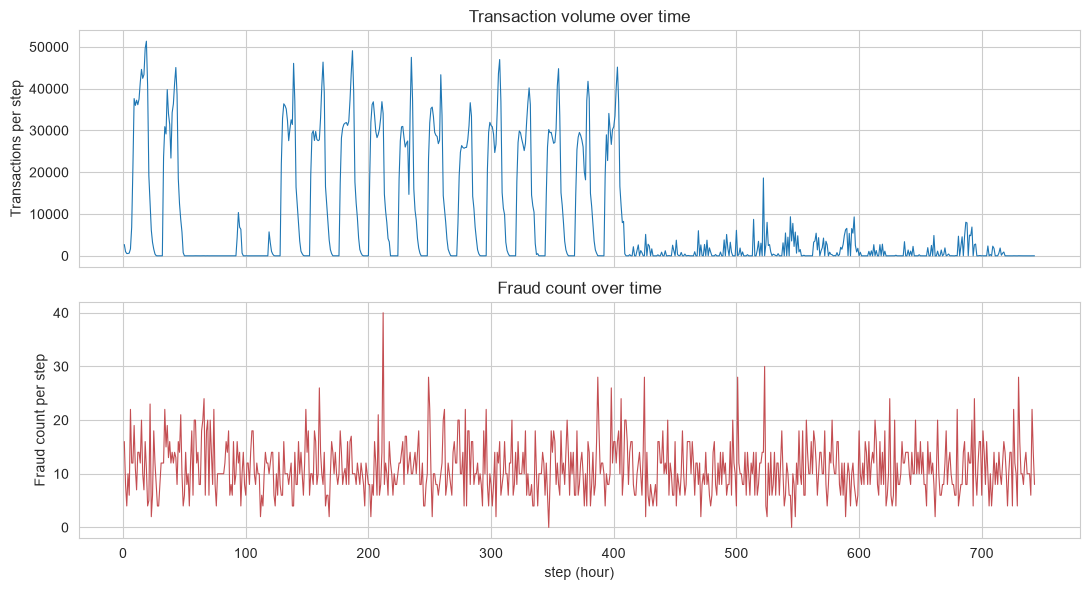

In [18]:
steps_summary = df.groupby('step').agg(
    n_transactions=('isFraud', 'size'),
    n_fraud=('isFraud', 'sum'),
).reset_index()
steps_summary['fraud_rate_pct'] = (steps_summary['n_fraud'] / steps_summary['n_transactions'] * 100)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(steps_summary['step'], steps_summary['n_transactions'], linewidth=0.8)
axes[0].set_ylabel('Transactions per step')
axes[0].set_title('Transaction volume over time')

axes[1].plot(steps_summary['step'], steps_summary['n_fraud'], linewidth=0.8, color='#C44E52')
axes[1].set_ylabel('Fraud count per step')
axes[1].set_xlabel('step (hour)')
axes[1].set_title('Fraud count over time')

plt.tight_layout()
plt.savefig('../reports/figures/volume_and_fraud_over_time.png', dpi=120)
plt.show()

In [19]:
# The 5 steps with the lowest volume
steps_summary.sort_values('n_transactions').head(5)

,step,n_transactions,n_fraud,fraud_rate_pct
661,662,2,2,100.0
111,112,2,2,100.0
28,29,4,4,100.0
626,627,4,4,100.0
654,655,4,4,100.0


In [20]:
# The 5 steps with the highest volume
steps_summary.sort_values('n_transactions', ascending=False).head(5)

,step,n_transactions,n_fraud,fraud_rate_pct
18,19,51352,11,0.021421
17,18,49579,16,0.032272
186,187,49083,10,0.020374
234,235,47491,10,0.021057
306,307,46968,16,0.034066


**What we see:**

- Volume goes up and down in daily cycles until about step 400. After that it drops and stays low.
- Fraud does not follow this. There are about 10 frauds per step during the whole simulation.
- The lowest-volume steps have a 100% fraud rate, but they only have 2 to 4 transactions. This is too small to mean anything.
- The busiest steps have a fraud rate of only 0.02% to 0.03%, far below the overall rate (about 0.13%). Fraud stays flat while volume grows, so the rate drops.

So the fraud rate is much higher after step 400. This could matter for a time-based train/test split. We look at it in the EDA.

## 2. Zero-Amount Transactions

A transaction with `amount == 0` is strange. Does it happen, and are these transactions fraud?

In [21]:
zero_amount = df[df['amount'] == 0]
print(f'Zero-amount transactions: {len(zero_amount):,} ({len(zero_amount) / len(df) * 100:.4f}% of all rows)')
print()
print('isFraud breakdown for zero-amount transactions:')
print(zero_amount['isFraud'].value_counts())
print()
print('Type breakdown for zero-amount transactions:')
print(zero_amount['type'].value_counts())

Zero-amount transactions: 16 (0.0003% of all rows)

isFraud breakdown for zero-amount transactions:
isFraud
1    16
Name: count, dtype: int64

Type breakdown for zero-amount transactions:
type
CASH_OUT    16
CASH_IN      0
DEBIT        0
PAYMENT      0
TRANSFER     0
Name: count, dtype: int64


All 16 zero-amount transactions are fraud, and all of them are `CASH_OUT`. There are very few of them, so they change nothing for the project. But a transaction of 0 is not normal, so it may be another side effect of the simulation.

## 3. Account Overlap Between nameOrig and nameDest

Do some accounts appear both as sender and as receiver? This matters if we later build features from the history of each account.

In [22]:
orig_accounts = set(df['nameOrig'].unique())
dest_accounts = set(df['nameDest'].unique())
overlap = orig_accounts & dest_accounts

print(f'Unique nameOrig: {len(orig_accounts):,}')
print(f'Unique nameDest: {len(dest_accounts):,}')
print(f'Accounts appearing as both sender and receiver: {len(overlap):,}')

Unique nameOrig: 6,353,307
Unique nameDest: 2,722,362
Accounts appearing as both sender and receiver: 1,769


Only 1,769 accounts are both sender and receiver (0.03% of senders). Also, there are 6.35M unique senders for 6.36M rows, so almost every sender appears only once. Features based on the history of a sender account will have almost nothing to work with.

In [23]:
# Account IDs start with 'C' (customer) or 'M' (merchant).
# Merchants should only receive money.
print('nameOrig prefixes:')
print(df['nameOrig'].str[0].value_counts())
print()
print('nameDest prefixes:')
print(df['nameDest'].str[0].value_counts())

nameOrig prefixes:
nameOrig
C    6362620
Name: count, dtype: int64[pyarrow]

nameDest prefixes:
nameDest
C    4211125
M    2151495
Name: count, dtype: int64[pyarrow]


All senders (`nameOrig`) are customers. Receivers are `C` or `M`. The number of `M` accounts (2,151,495) is the same as the number of `PAYMENT` transactions, so `PAYMENT` always goes to a merchant and the other types go to customers. Fraud never happens in `PAYMENT`, so it never reaches a merchant either. Nothing new here.

## 4. Balance Consistency by Transaction Type

This is the main question. When money leaves the sender, the new balance should be `oldbalanceOrg - amount`. This cannot work for `CASH_IN`, because a deposit increases the balance. Fraud only happens in `CASH_OUT` and `TRANSFER`, so we compare fraud and non-fraud on these two types only.

In [24]:
relevant_types = ['CASH_OUT', 'TRANSFER']
df_relevant = df[df['type'].isin(relevant_types)].copy()
print(f'Rows with type in {relevant_types}: {len(df_relevant):,}')
print(df_relevant["isFraud"].value_counts())

Rows with type in ['CASH_OUT', 'TRANSFER']: 2,770,409
isFraud
0    2762196
1       8213
Name: count, dtype: int64


In [25]:
expected_new_balance = df_relevant['oldbalanceOrg'] - df_relevant['amount']
balance_diff = (df_relevant['newbalanceOrig'] - expected_new_balance).abs()
df_relevant['balance_orig_consistent'] = balance_diff < 0.01

print('Origin balance consistency, CASH_OUT/TRANSFER only, by class:')
df_relevant.groupby('isFraud')['balance_orig_consistent'].mean().round(4)

Origin balance consistency, CASH_OUT/TRANSFER only, by class:


isFraud
0    0.0949
1    0.9945
Name: balance_orig_consistent, dtype: float64

In [26]:
# Same check, broken down by type AND class, to see if CASH_OUT and TRANSFER behave differently.
df_relevant.groupby(['type', 'isFraud'])['balance_orig_consistent'].mean().round(4)

type      isFraud
CASH_OUT  0          0.1084
          1          0.9942
TRANSFER  0          0.0379
          1          0.9949
Name: balance_orig_consistent, dtype: float64

The gap is still huge with only `CASH_OUT` and `TRANSFER`: the formula holds for 99.5% of fraud rows but only 9.5% of non-fraud rows. Both types show the same pattern. So the difference does not come from mixing different transaction types.

It is also strange. The formula should work for normal transactions, but it works for only about 1 in 10 of them.

In [27]:
expected_new_dest = df_relevant['oldbalanceDest'] + df_relevant['amount']
dest_diff = (df_relevant['newbalanceDest'] - expected_new_dest).abs()
df_relevant['balance_dest_consistent'] = dest_diff < 0.01

print('Destination balance consistency, CASH_OUT/TRANSFER only, by class:')
df_relevant.groupby('isFraud')['balance_dest_consistent'].mean().round(4)

Destination balance consistency, CASH_OUT/TRANSFER only, by class:


isFraud
0    0.7742
1    0.4350
Name: balance_dest_consistent, dtype: float64

The destination formula (`oldbalanceDest + amount`) holds less often for fraud (43.5%) than for non-fraud (77.4%). The next check shows why.

In [28]:
zero_dest_balance = (df_relevant['oldbalanceDest'] == 0) & (df_relevant['newbalanceDest'] == 0)
print('Destination balance stuck at zero, CASH_OUT/TRANSFER only, by class:')
df_relevant.groupby('isFraud').apply(lambda g: zero_dest_balance.loc[g.index].mean()).round(4)

Destination balance stuck at zero, CASH_OUT/TRANSFER only, by class:


isFraud
0    0.0006
1    0.4963
dtype: float64

This is the biggest result of the notebook. For non-fraud, the destination balance is almost never 0 before and after (0.06%, about 1,700 rows out of 2.76M). For fraud it happens 49.6% of the time, about 1 case in 2. This explains most of the fraud rows that failed the previous check.

It matches the PaySim documentation: the simulator does not always update the destination balance when it creates a fraud transaction. So `newbalanceOrig` and `newbalanceDest` probably carry a simulation artifact.

## 5. Negative or Invalid Values

In [29]:
cols_to_check = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
negative_counts = (df[cols_to_check] < 0).sum()
print('Negative value counts per column:')
print(negative_counts)

Negative value counts per column:
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64


No negative values in `amount` or in the balance columns.

## 6. Summary

- **Step**: volume has daily cycles until step ~400, then stays low. Fraud stays flat (about 10 per step), so the fraud rate is much higher after step 400.
- **Zero amount**: 16 transactions, all fraud and all `CASH_OUT`.
- **Account overlap**: only 1,769 accounts are both sender and receiver. Almost every sender appears once, so account history will not help much.
- **Account IDs**: all senders are customers. Merchants (`M`) only receive `PAYMENT`.
- **Balance consistency (main question)**: the gap stays when we look only at `CASH_OUT` and `TRANSFER`. The origin formula holds for 99.5% of fraud vs 9.5% of non-fraud. The destination balance is stuck at 0 for 49.6% of fraud vs 0.06% of non-fraud.
- **Invalid values**: no negative values.

## 7. Decisions and Next Steps

**Observation:** `newbalanceOrig` and `newbalanceDest` are very different between fraud and non-fraud, even inside `CASH_OUT` and `TRANSFER`.

**Decision:** we treat them as a leakage risk and leave them out of the realistic model. We will confirm this later by comparing a model with these columns and a model without them.


**Next:** `03_eda.ipynb`, with a focus on the change around step 400 and on features available before the transaction.